# ۱۲ - گزارش نهایی مدیریتی

این نوتبوک پنج یافته مهم، سه پیشنهاد عملی و شاخص‌های پایش را از اعداد واقعی می‌سازد و فایل‌های گزارش را تولید می‌کند.

## ۲. سؤال‌های کسب‌وکاری

1. خلاصه وضعیت کسب‌وکار چیست؟
2. پنج یافته مهم پروژه کدام‌اند؟
3. سه پیشنهاد عملی برای مدیریت چیست؟
4. چه شاخص‌هایی را باید در آینده پایش کرد؟
5. محدودیت‌های اصلی تحلیل چیست؟

## ۱. عنوان و هدف

این نوتبوک پنج یافته مهم، سه پیشنهاد عملی و شاخص‌های پایش را از اعداد واقعی می‌سازد و فایل‌های گزارش را تولید می‌کند.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

گزارش از فایل `reports/metrics.json` و جداول `reports/tables/` ساخته می‌شود؛ بنابراین اعداد آن با نوتبوک‌های قبلی یکسان است.

## خلاصه وضعیت کسب‌وکار

In [2]:
totals = headline["business_totals"]
display(pd.Series(totals, name="value"))

avg_items_per_order     1.141700e+00
delivered_orders        9.647800e+04
freight_brl             2.251910e+06
item_revenue_brl        1.359164e+07
mean_item_price_brl     1.206500e+02
mean_order_value_brl    1.593300e+02
orders                  9.944100e+04
product_categories      7.300000e+01
total_paid_brl          1.600887e+07
unique_buyers           9.609600e+04
unique_products         3.295100e+04
unique_sellers          3.095000e+03
Name: value, dtype: float64

In [3]:
display(pd.Series(headline["growth"], name="value"))

core_months                              20
core_orders                           99092
first6_to_last6_pct_change         173.7253
first_core_month                    2017-01
first_core_month_orders                 800
jan_aug_2017_orders                   22968
jan_aug_2018_orders                   53991
last_core_month                     2018-08
last_core_month_orders                 6512
mean_orders_first_6_core_months      2435.2
mean_orders_last_6_core_months       6665.7
peak_month                          2017-11
peak_month_orders                      7544
peak_over_median_ratio                1.464
total_orders                          99441
trough_month                        2017-01
trough_month_orders                     800
yoy_jan_aug_pct_change             135.0705
Name: value, dtype: object

In [4]:
display(pd.Series(headline["satisfaction"], name="value"))

mean_score                      4.0864
median_score                    5.0000
n_items                    112650.0000
n_orders                    99441.0000
n_orders_with_review        98673.0000
n_orders_without_review       768.0000
pct_1                          11.5158
pct_1_or_2                     14.6889
pct_4_or_5                     77.0687
pct_5                          57.7747
pct_orders_with_review         99.2277
Name: value, dtype: float64

In [5]:
display(pd.Series(headline["delay_vs_satisfaction"], name="value"))

late_orders_at_risk             6381
mean_score_late                 2.27
mean_score_on_time_or_early     4.29
min_sample_reached              True
n_late                          6381
n_on_time_or_early             89443
score_gap                       2.02
Name: value, dtype: object

## پنج یافته مهم

In [6]:
from olist_analysis.reporting import build_content, load_tables
content = build_content(headline, load_tables())
for f in content.findings:
    print(f"یافته {f.number}: {f.title}")
    print(f"  نتیجه: {f.statement}")
    print(f"  نمودار: {f.figure}")
    print()

یافته 1: رشد سریع کسبوکار در ۲۰۱۷ و سپس تثبیت در سطح بالاتر در ۲۰۱۸
  نتیجه: حجم سفارشها از آغاز فعالیت رشد چشمگیری داشته است، اما این رشد یکنواخت نبوده؛ پس از جهش آبان ۲۰۱۷ و فروردین ۲۰۱۸، سطح فعالیت تقریباً ثابت شده و الگوی فصلی قابل تشخیصی نیز دیده نمیشود.
  نمودار: fig_02_monthly_orders.png

یافته 2: تمرکز شدید بازار در پنج ایالت و یک شهر
  نتیجه: بازار Olist بهشدت متمرکز است: نزدیک به نیمی از خریداران در یک ایالت و بیش از سهچهارم آنان در پنج ایالت زندگی میکنند.
  نمودار: fig_05_state_customers.png

یافته 3: تأخیر در تحویل، قویترین عامل همراه با افت رضایت مشتری
  نتیجه: سفارشهای دیرکرددار بخش کوچکی از سفارشها را تشکیل میدهند، اما میانگین امتیاز آنان بسیار پایینتر است؛ و هرچه تأخیر طولانیتر باشد، افت امتیاز شدیدتر میشود.
  نمودار: fig_22_delay_satisfaction.png

یافته 4: تأخیر در تحویل الگویی منطقهای دارد، نه تصادفی
  نتیجه: زمان تحویل و نرخ تأخیر در ایالتهای شمال و شمالشرق بهطور نظاممند بدتر از ایالتهای جنوب و جنوبشرق است؛ یعنی مسئله بیشتر عملیاتی و منطقهای است تا عمومی.
  نمودار: f

In [7]:
for f in content.findings:
    print(f"یافته {f.number} - شواهد عددی:")
    for e in f.evidence:
        print("   -", e)
    print(f"  اهمیت: {f.importance}")
    print(f"  محدودیت: {f.limitation}")
    print()

یافته 1 - شواهد عددی:
   - تعداد سفارشها از 800 در 2017-01 به اوج 7,544 در 2017-11 رسیده است.
   - مقایسه همدوره ژانویه تا اوت: 22,968 سفارش در ۲۰۱۷ برابر با 53,991 سفارش در ۲۰۱۸، یعنی 135.07 درصد افزایش.
   - میانگین سفارش ششماهه نخست پنجره تحلیلی 2,435.2 و ششماهه پایانی 6,665.7 سفارش در ماه است.
   - سه ماه پایانی پنجره بهطور میانگین 6,323.7 سفارش در ماه دارد، در برابر 2,435.2 سفارش در شش ماه نخست این پنجره.
  اهمیت: برنامهریزی ظرفیت انبار، پشتیبانی و ارسال باید بر پایه سطح فعلی تقاضا انجام شود، نه بر پایه نرخ رشد ۲۰۱۷. همچنین نبود الگوی فصلی روشن یعنی نمیتوان برای کمپینها به «فصل اوج» تکیه کرد.
  محدودیت: مقایسه همدوره، یک سال راهاندازی را با یک سال تثبیتشده میسنجد و بنابراین درصد رشد را بیش از حد نشان میدهد. ماههای ۲۰۱۶ و دو ماه پایانی ۲۰۱۸ بهدلیل ناقص بودن از تحلیل روند کنار گذاشته شدهاند.

یافته 2 - شواهد عددی:
   - 96,096 خریدار یکتا در 27 ایالت شناسایی شده است.
   - پنج ایالت نخست (SP, RJ, MG, RS, PR) روی هم 77.08 درصد خریداران و 77.18 درصد سفارشها را در اختیار دارند.
   - ایال

## سه پیشنهاد عملی

In [8]:
for r in content.recommendations:
    print(f"پیشنهاد {r.number}: {r.title}")
    print(f"  مسئله: {r.problem}")
    print(f"  یافته پشتیبان: {r.supporting_finding}")
    print(f"  تغییر مورد انتظار: {r.expected_change}")
    print("  شاخص‌های پایش:")
    for k in r.monitoring_kpi:
        print("   -", k)
    print()

پیشنهاد 1: کاهش تأخیر تحویل در 8 ایالت دارای وضعیت نامطلوب
  مسئله: 6.77 درصد سفارشهای تحویلشده دیرکرددار هستند و در ایالتهای شمال و شمالشرق این نرخ چند برابر ایالتهای جنوب و جنوبشرق است.
  یافته پشتیبان: یافته ۳ و ۴: اختلاف 2.02 امتیازی میان دو گروه تحویل، و نرخ تأخیر 21.41 درصد در AL.
  تغییر مورد انتظار: کاهش نرخ تأخیر و در پی آن افزایش میانگین امتیاز سفارشهای همان ایالتها؛ حتی کاهش چند درصدی سهم سفارشهای دیرکرددار میتواند میانگین امتیاز کل را بهطور محسوس بالا ببرد.
  شاخص‌های پایش:
   - نرخ سفارشهای دیرکرددار به تفکیک ایالت (ماهانه)
   - میانگین روزهای تأخیر در میان سفارشهای دیرکرددار
   - میانگین امتیاز سفارشهای دیرکرددار در برابر بهموقع

پیشنهاد 2: بازتنظیم وعده تحویل بر اساس عملکرد واقعی هر منطقه
  مسئله: بهطور میانگین سفارشها 11.18 روز زودتر از وعده اعلامشده تحویل میشوند؛ یعنی وعده فعلی در کل حاشیه امن بزرگی دارد و در برخی مناطق بیش از حد محافظهکارانه است.
  یافته پشتیبان: یافته ۴: میانگین زمان تحویل در AL 24.54 روز است، در حالی که وعده اعلامی برای همان ایالت طولانیتر است (جدول

## شاخص‌های پیشنهادی برای پایش آینده

In [9]:
display(pd.DataFrame(content.monitoring_indicators, columns=["شاخص", "تعریف"]))

,شاخص,تعریف
0,نرخ سفارشهای دیرکرددار,درصد سفارشهای تحویلشده با تأخیر بیشتر از تاریخ...
1,میانگین زمان تحویل,میانگین فاصله ثبت سفارش تا تحویل واقعی، به تفک...
2,میانگین امتیاز مشتری,میانگین review_score و سهم امتیازهای ۱ و ۲
3,سهم امتیازهای ۱ و ۲ در سفارشهای دیرکرددار,بهعنوان شاخص هشدار زودهنگام تجربه مشتری
4,سهم خریداران بازگشتی,درصد خریداران با بیش از یک سفارش (اکنون 3.12 د...
5,سهم پنج دستهبندی نخست از مبلغ فروش,برای پایش تمرکز درآمد
6,سهم پنج ایالت نخست از سفارشها,برای پایش تمرکز بازار


## محدودیت‌های اصلی

In [10]:
for limitation in content.limitations:
    print("-", limitation)

- همه یافتهها همبستگی توصیفی هستند؛ هیچ آزمون علّی یا آزمایش کنترلشدهای انجام نشده است.
- مبلغ فروش از ستون price جدول اقلام سفارش محاسبه شده و با درآمد خالص یا سود شرکت یکسان نیست.
- سفارشهای لغوشده و ناموجود در تحلیلهای تحویل و رضایت وارد نشدهاند؛ بنابراین نتایج آن تحلیلها فقط برای سفارشهای تحویلشده معتبر است.
- ماههای سال ۲۰۱۶ و دو ماه پایانی سال ۲۰۱۸ از تحلیل روند کنار گذاشته شدهاند؛ اما آمار کل بر پایه همه داده است.
- متن نظرات مشتریان در تحلیل کمّی استفاده نشده است؛ 58.70 درصد نظرات هیچ متن توضیحی ندارند.
- داده شامل هزینه بازاریابی، موجودی انبار، رقبا و اطلاعات جمعیتشناختی مشتریان نیست.


## ساخت فایل‌های گزارش

In [11]:
from olist_analysis.reporting import build_report
result = build_report()
print("Markdown:", result["markdown"])
print("PDF     :", result["pdf"])

Markdown: /workspace/chats/86635db235004c1b8518383d/reports/executive_report.md
PDF     : /workspace/chats/86635db235004c1b8518383d/reports/executive_report.pdf


## ۷. نمودارها

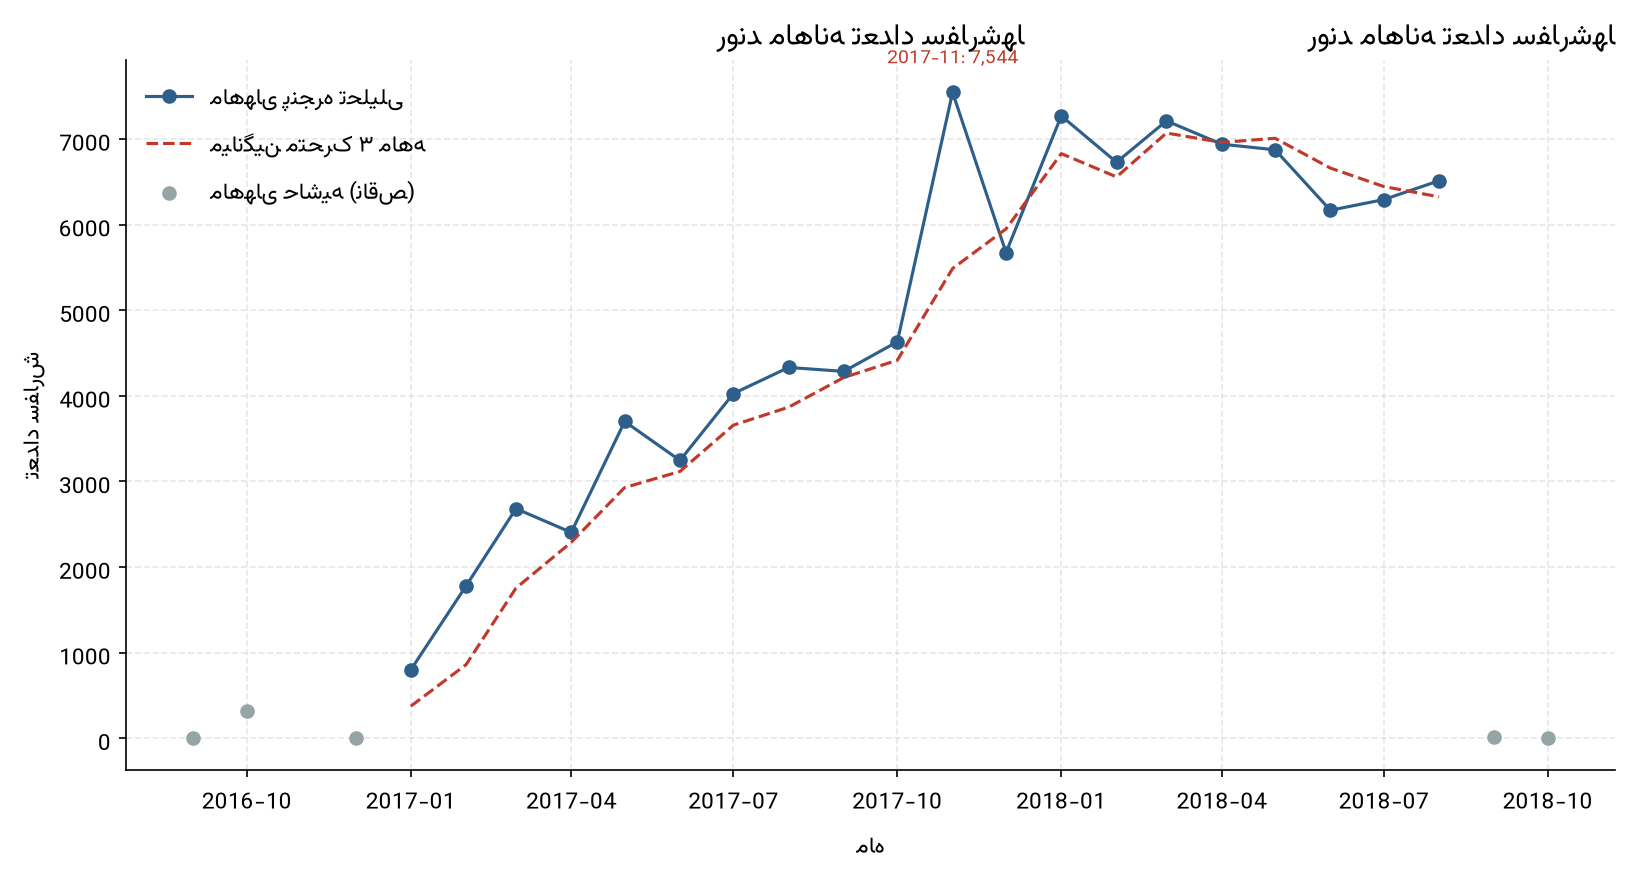

نمودار ۲ - روند ماهانه سفارشها؛ ماههای حاشیه از تحلیل روند کنار گذاشته شدهاند


In [12]:
display(Image(filename=str(FIGURES_DIR / "fig_02_monthly_orders.png"), width=920))
caption = FIGURES_DIR / "fig_02_monthly_orders.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

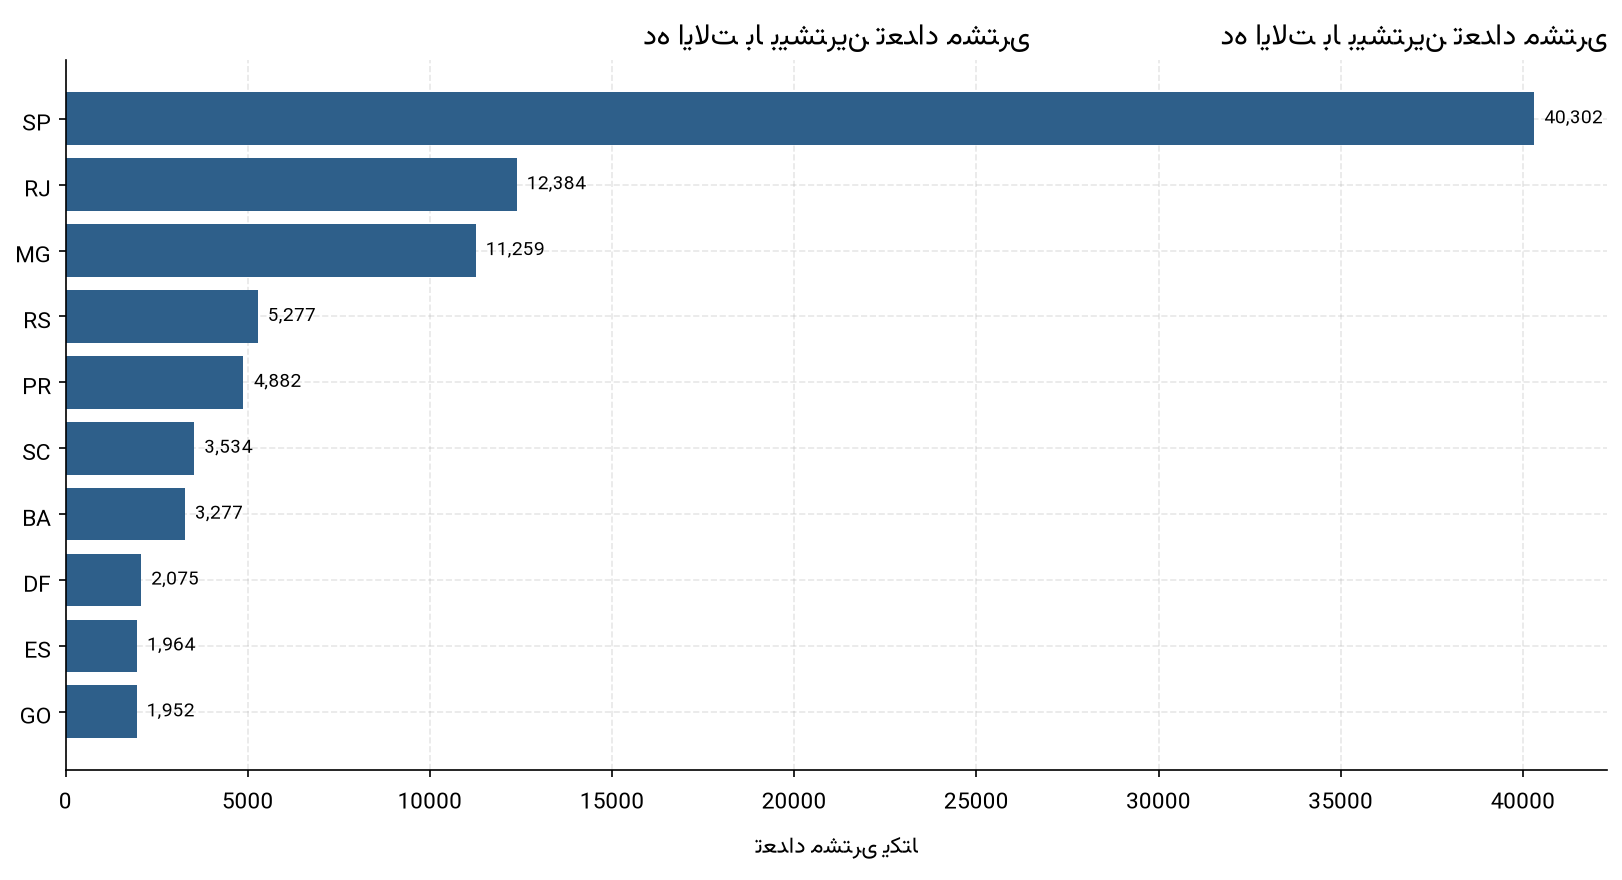

نمودار ۵ - ده ایالت اول بر اساس تعداد مشتری یکتا (customer_unique_id)


In [13]:
display(Image(filename=str(FIGURES_DIR / "fig_05_state_customers.png"), width=920))
caption = FIGURES_DIR / "fig_05_state_customers.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

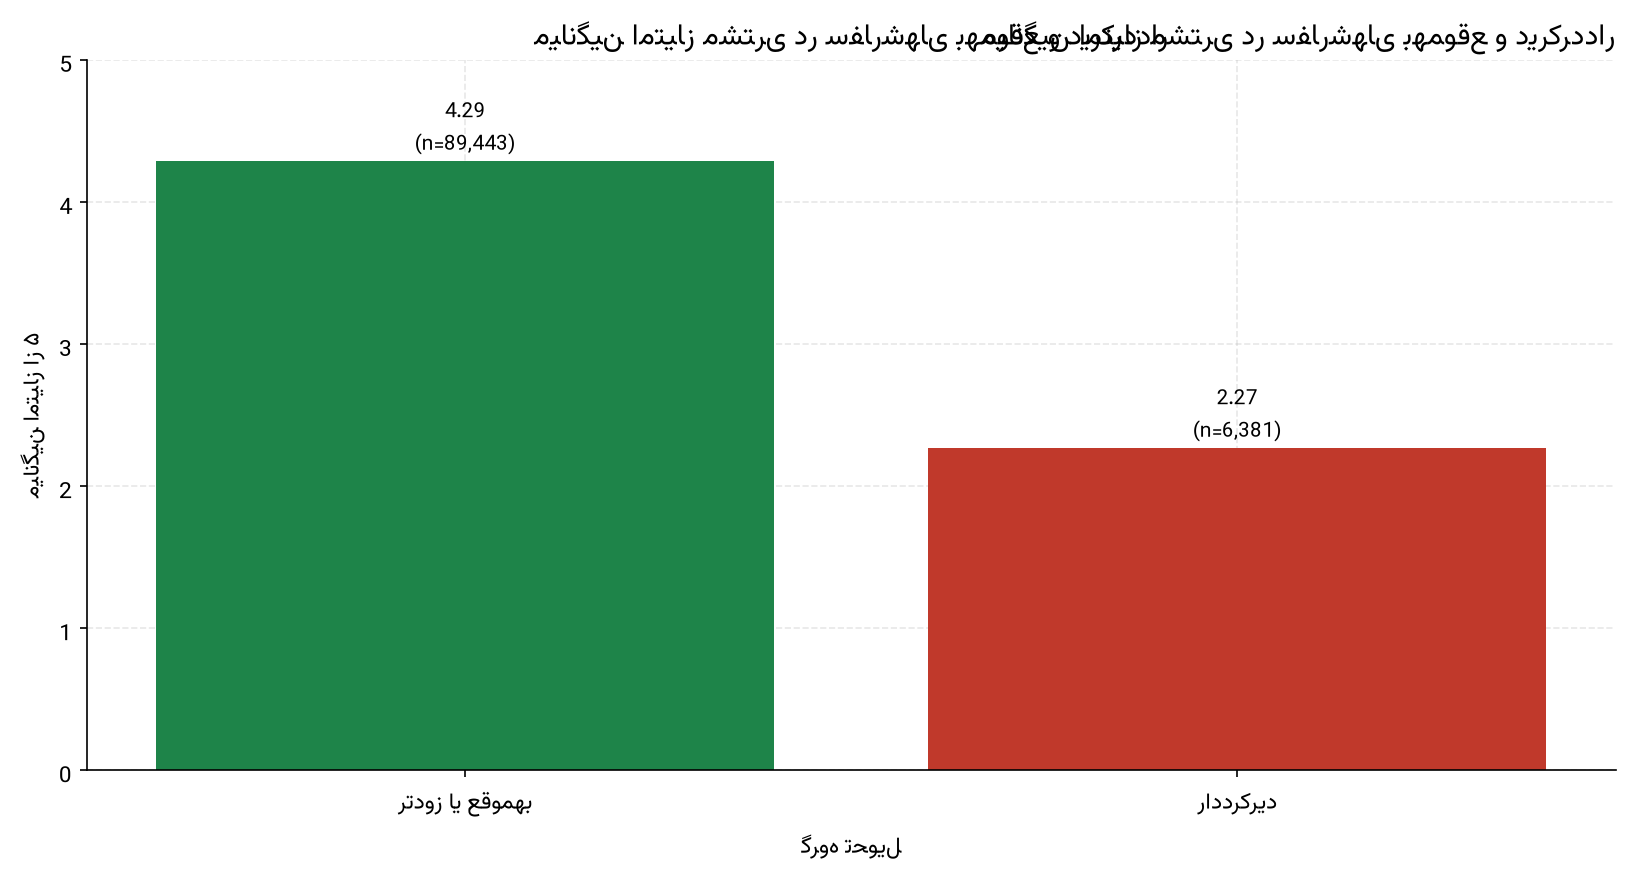

نمودار ۲۲ - اختلاف میانگین امتیاز دو گروه تحویل


In [14]:
display(Image(filename=str(FIGURES_DIR / "fig_22_delay_satisfaction.png"), width=920))
caption = FIGURES_DIR / "fig_22_delay_satisfaction.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

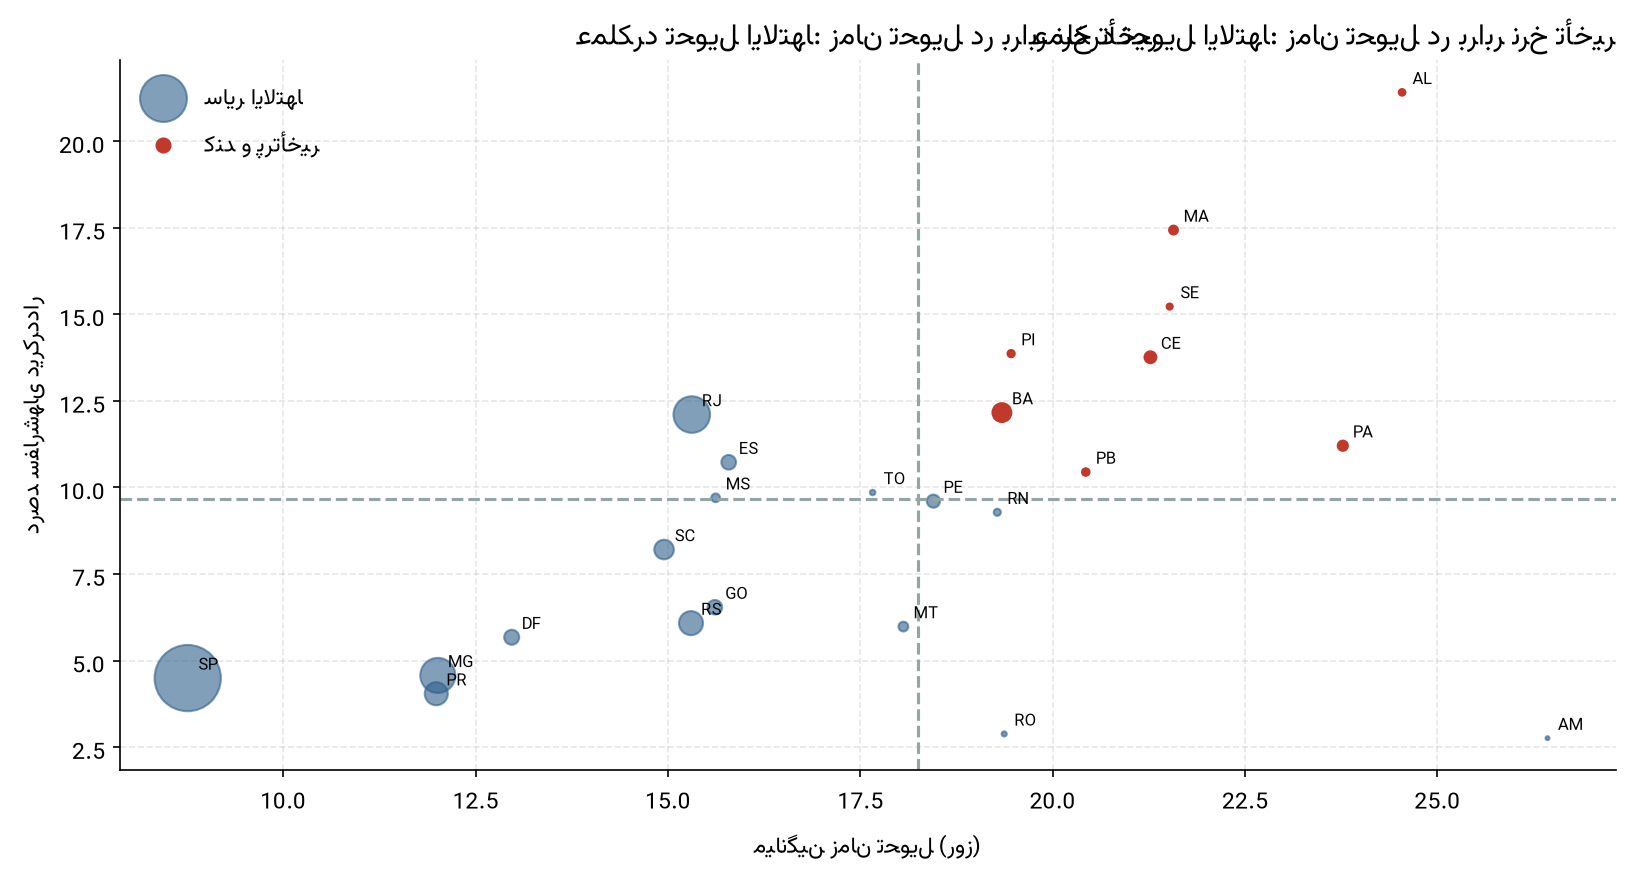

نمودار ۲۷ - تحلیل ترکیبی دوم؛ اندازه نقطه نشاندهنده تعداد سفارش است


In [15]:
display(Image(filename=str(FIGURES_DIR / "fig_27_combined_geography_delivery.png"), width=920))
caption = FIGURES_DIR / "fig_27_combined_geography_delivery.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

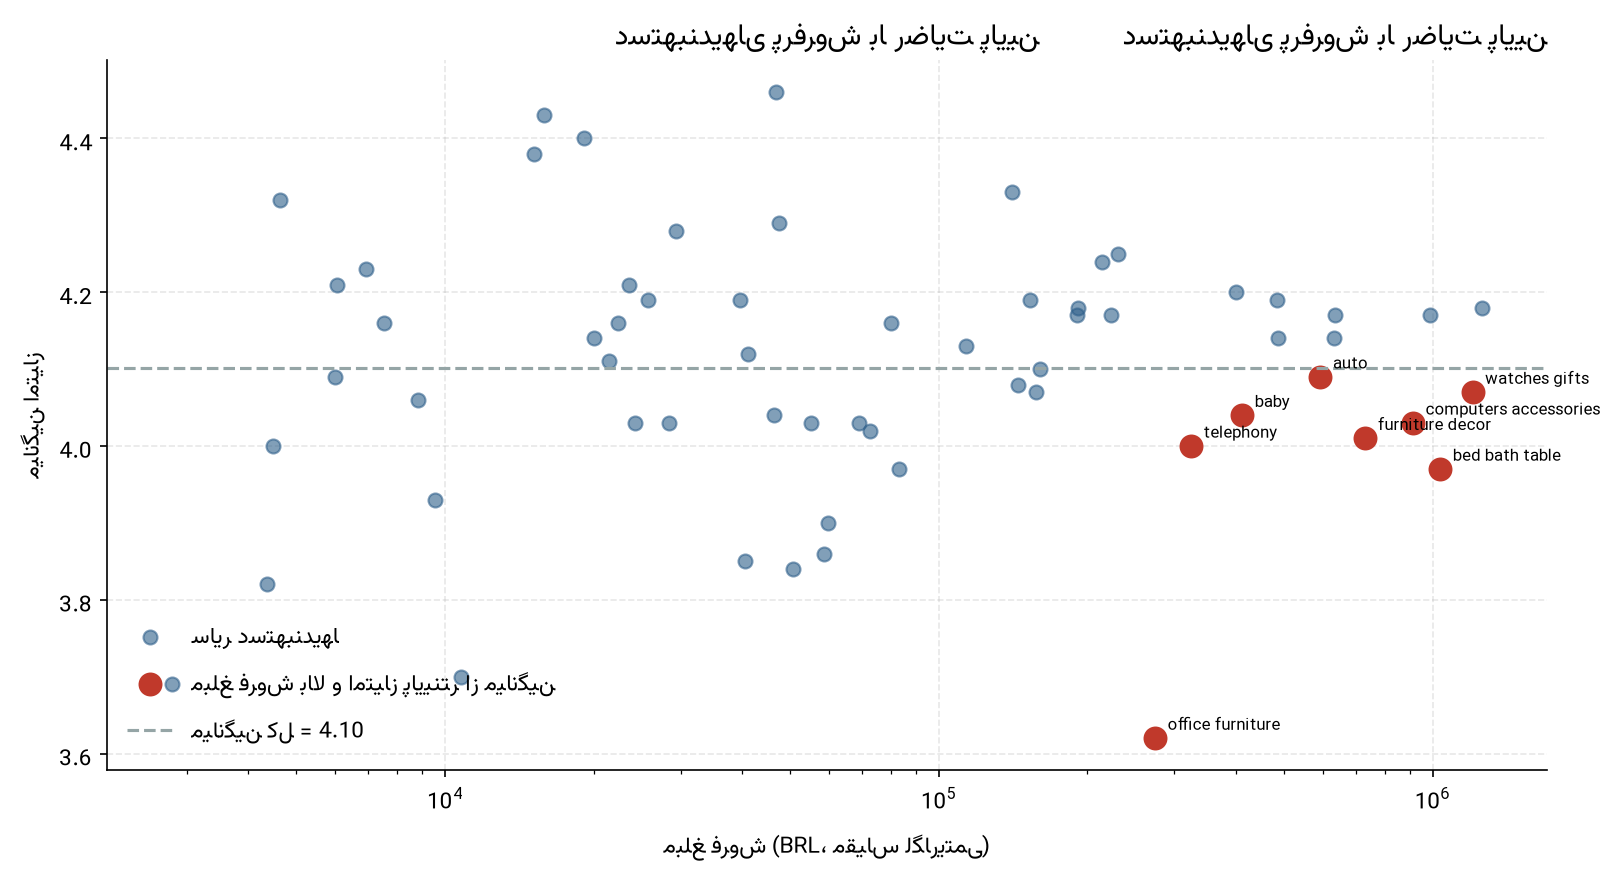

نمودار ۲۶ - تحلیل ترکیبی اول: دستهبندیهای نیازمند بررسی


In [16]:
display(Image(filename=str(FIGURES_DIR / "fig_26_combined_revenue_vs_score.png"), width=920))
caption = FIGURES_DIR / "fig_26_combined_revenue_vs_score.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۱۱. نتیجه‌گیری

گزارش مدیریتی در `reports/executive_report.md` و `reports/executive_report.pdf` تولید شد. خروجی این نوتبوک، نسخه قابل ارائه به مدیریت است و هیچ کد برنامه‌نویسی در آن دیده نمی‌شود.